# 01. Unit economics and the switching value

Tests **H1**, the primary hypothesis. Every other notebook in this repo serves
this one.

| | |
|---|---|
| **Statement** | `alpha* > 1`, so migrating an order from Zomato's marketplace to Bistro's owned kitchen raises group contribution regardless of the cannibalisation rate |
| **Test** | Compute `alpha*` from the unit economics model at `retention = 1` and across the plausible retention range. Run the sensitivity grid. |
| **Kill condition** | `alpha*` falls below 1 at `retention = 1`, and below the plausible range for actual alpha |

## The model

```
CM_net = CM_bistro - (alpha * retention * CM_zomato)
alpha* = CM_bistro / (retention * CM_zomato)
```

`alpha` is the share of Bistro orders that would otherwise have been Zomato
food delivery orders. `retention` is the share of those Eternal would actually
have kept, given Swiggy Bolt, Snacc and Zepto Cafe exist. Setting `retention`
to 1 is the conservative case and gives the lowest threshold the evidence
supports.

**Do not write the verdict before the last cell runs.** A disproved hypothesis
with a clean method is a better result than a confirmed one with a rigged test.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config, panel, metrics, viz, unit_economics as ue

viz.apply_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

panel.assert_reviewed()  # refuses to run on an unvalidated panel

df = pd.read_csv(config.PROCESSED / "eternal_quarterly_enriched.csv")
df = metrics.sort_by_quarter(df)
len(df)

15

## Step 1. CM_zomato from the filings

This is the better of the two numbers and it deserves the higher confidence in
the deck.

Adjusted EBITDA per order is a **floor**, not a contribution margin, because
fixed cost sits inside that line. The add back is the share of food delivery
revenue treated as fixed. It is an assumption and it belongs in
`ASSUMPTIONS.md` with its reasoning, not in a cell comment.

In [2]:
# Eternal discloses food delivery Contribution and publishes its definition, so
# CM_zomato is read rather than assumed. No add back is required.
cmz = ue.cm_zomato_from_contribution(df)
cm_zomato = float(cmz["cm_zomato"].dropna().iloc[-1])
print(f"CM_zomato, latest quarter: {cm_zomato:.2f} per Rs 100 of NOV")
cmz.dropna().round(3)

CM_zomato, latest quarter: 10.19 per Rs 100 of NOV


,quarter,cm_pct_nov,cm_zomato
5,Q4FY24,0.088,8.805
6,Q1FY25,0.085,8.489
7,Q2FY25,0.089,8.876
8,Q3FY25,0.100,9.985
9,Q4FY25,0.103,10.256
10,Q1FY26,0.099,9.870
11,Q2FY26,0.104,10.358
12,Q3FY26,0.104,10.390
13,Q4FY26,0.102,10.229
14,Q1FY27,0.102,10.187


Adjusted EBITDA floor     5.63 per Rs 100 of NOV
Disclosed Contribution   10.19   <- use this, no assumption
Floor + 40% add back     18.76


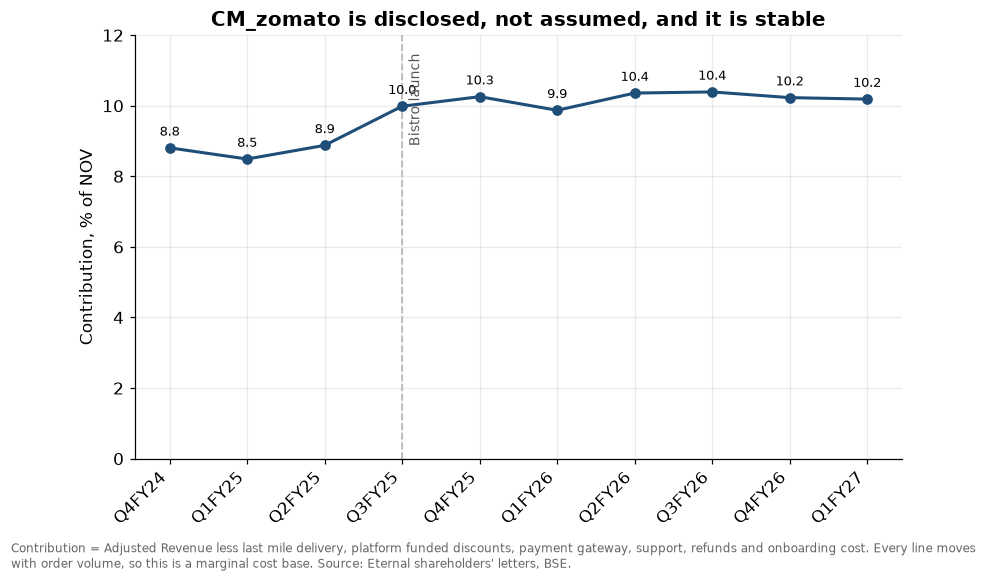

In [3]:
# Cross check the disclosed figure against the add back path the brief proposed.
# The disclosed number must sit above the Adjusted EBITDA floor and below the
# floor plus a generous add back. If it does not, one of the two is misread.
floor    = ue.cm_zomato_from_filings(df, 0.00)["cm_zomato"].dropna().iloc[-1]
generous = ue.cm_zomato_from_filings(df, 0.40)["cm_zomato"].dropna().iloc[-1]
print(f"Adjusted EBITDA floor    {floor:5.2f} per Rs 100 of NOV")
print(f"Disclosed Contribution   {cm_zomato:5.2f}   <- use this, no assumption")
print(f"Floor + 40% add back     {generous:5.2f}")
assert floor < cm_zomato < generous

d = cmz.dropna()
fig, ax = plt.subplots()
ax.plot(d["quarter"], d["cm_zomato"], marker="o", lw=2, color=viz.PALETTE["fd"])
for x, y in zip(d["quarter"], d["cm_zomato"]):
    ax.annotate(f"{y:.1f}", (x, y), textcoords="offset points", xytext=(0, 8),
                ha="center", fontsize=8.5)
ax.set_ylim(0, 12)
ax.set_ylabel("Contribution, % of NOV")
ax.set_title("CM_zomato is disclosed, not assumed, and it is stable")
plt.xticks(rotation=45, ha="right")
viz.mark_event(ax, config.BISTRO_START_QUARTER, d["quarter"].tolist(), "Bistro launch")
viz.caption(fig, "Contribution = Adjusted Revenue less last mile delivery, platform funded "
                 "discounts, payment gateway, support, refunds and onboarding cost. Every "
                 "line moves with order volume, so this is a marginal cost base. "
                 "Source: Eternal shareholders' letters, BSE.")
viz.save(fig, "h1_cm_zomato_series")
plt.show()

## Step 2. CM_bistro cannot be estimated honestly, so invert the question

Bistro has no standalone P&L. It sits inside an `Others` segment that also
carries Nugget and Greening India. Menu prices have not been sampled, so the
order value line of the stack is empty.

Guessing the number and dressing the guess in a sensitivity range would be
worse than saying so. The switching value inverts cleanly:

```
required CM_bistro = alpha * retention * CM_zomato
```

State the bar and let the reader judge whether a 10 minute owned kitchen on a
Rs 50-150 ticket clears it. At `alpha = 1` and `retention = 1` the bar collapses
to `CM_bistro > CM_zomato`: the whole question becomes whether the owned kitchen
earns more per rupee of order value than the marketplace does.

In [4]:
for r in config.RETENTION_GRID:
    t = ue.required_cm_bistro(cm_zomato, config.ALPHA_GRID + [1.0], retention=r)
    row = "  ".join(f"a={a:.0%}: {v:.2f}%" for a, v in zip(t.alpha, t.required_cm_bistro))
    print(f"retention {r:>5.0%} |  {row}")

retention  100% |  a=20%: 2.04%  a=40%: 4.07%  a=60%: 6.11%  a=80%: 8.15%  a=95%: 9.68%  a=100%: 10.19%
retention   75% |  a=20%: 1.53%  a=40%: 3.06%  a=60%: 4.58%  a=80%: 6.11%  a=95%: 7.26%  a=100%: 7.64%
retention   50% |  a=20%: 1.02%  a=40%: 2.04%  a=60%: 3.06%  a=80%: 4.07%  a=95%: 4.84%  a=100%: 5.09%


## Step 3. The central exhibit

The frontier, with the marketplace's own margin marked. Everything above a line
is accretive at that retention assumption. Everything below is dilutive.

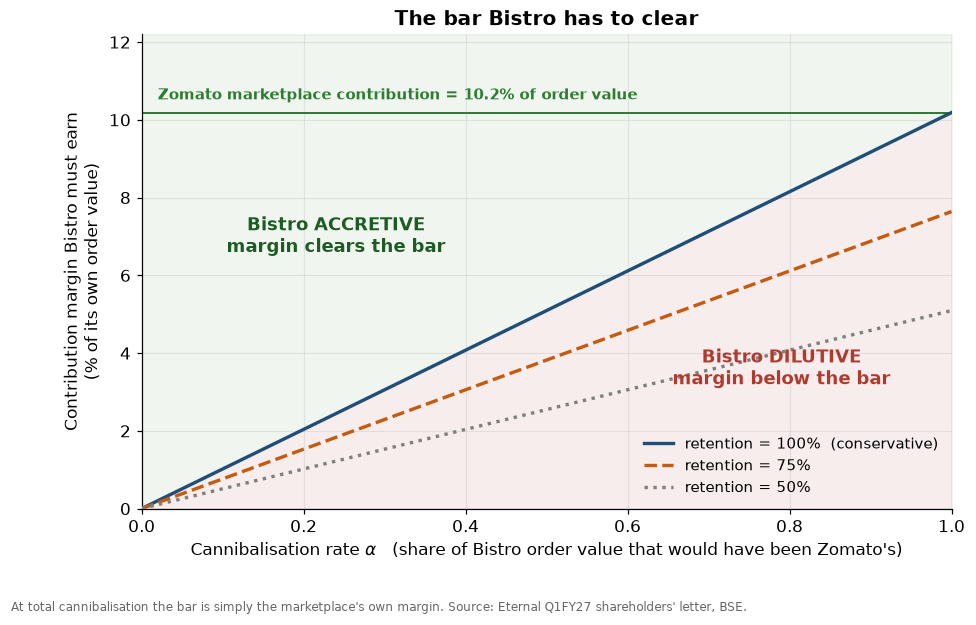

In [5]:
fig, ax = plt.subplots(figsize=(9.5, 5.6))
a = np.linspace(0, 1, 101)
ax.fill_between(a, 0, a * cm_zomato, color=viz.PALETTE["negative"], alpha=0.09, zorder=0)
ax.fill_between(a, a * cm_zomato, 12.2, color=viz.PALETTE["positive"], alpha=0.07, zorder=0)
for r, ls, c in [(1.00, "-", viz.PALETTE["fd"]),
                 (0.75, "--", viz.PALETTE["qc"]),
                 (0.50, ":", viz.PALETTE["control"])]:
    ax.plot(a, a * r * cm_zomato, ls, color=c, lw=2.2, zorder=3,
            label=f"retention = {r:.0%}" + ("  (conservative)" if r == 1 else ""))
ax.axhline(cm_zomato, color=viz.PALETTE["accent"], lw=1.3, zorder=2)
ax.annotate(f"Zomato marketplace contribution = {cm_zomato:.1f}% of order value",
            xy=(0.02, cm_zomato + 0.25), fontsize=9.5, va="bottom",
            color=viz.PALETTE["accent"], fontweight="bold", zorder=4)
ax.text(0.24, 6.6, "Bistro ACCRETIVE\nmargin clears the bar", fontsize=11.5,
        color="#1d5c22", fontweight="bold", ha="center", zorder=4)
ax.text(0.79, 3.2, "Bistro DILUTIVE\nmargin below the bar", fontsize=11.5,
        color=viz.PALETTE["negative"], fontweight="bold", ha="center", zorder=4)
ax.set_xlabel(r"Cannibalisation rate $\alpha$   (share of Bistro order value that would have been Zomato's)")
ax.set_ylabel("Contribution margin Bistro must earn\n(% of its own order value)")
ax.set_title("The bar Bistro has to clear")
ax.set_xlim(0, 1); ax.set_ylim(0, 12.2)
ax.legend(loc="lower right", fontsize=9.5)
viz.caption(fig, "At total cannibalisation the bar is simply the marketplace's own margin. "
                 "Source: Eternal Q1FY27 shareholders' letter, BSE.")
viz.save(fig, "h1_required_cm_bistro")
plt.show()

## Step 4. How big is the stake, today?

A threshold only matters if the quantity it governs is material. Check that
before writing any recommendation.

In [6]:
last = df.iloc[-1]
scale = last.others_adj_revenue / last.fd_nov
worst = last.others_adj_revenue * cm_zomato / 100

print(f"Food delivery NOV            Rs {last.fd_nov:>9,.0f} cr")
print(f"Food delivery contribution   Rs {last.fd_contribution:>9,.0f} cr")
print(f"Others adjusted revenue      Rs {last.others_adj_revenue:>9,.0f} cr"
      "   (Bistro + Nugget + Greening India)")
print(f"Others as a share of fd NOV  {scale:>12.2%}   <- upper bound on Bistro")
print(f"\nWorst case: alpha = 1, retention = 1, CM_bistro = 0")
print(f"  contribution forgone       Rs {worst:>9.1f} cr per quarter")
print(f"  as a share of fd contribution {worst / last.fd_contribution:>9.2%}")

Food delivery NOV            Rs    10,769 cr
Food delivery contribution   Rs     1,097 cr
Others adjusted revenue      Rs        95 cr   (Bistro + Nugget + Greening India)
Others as a share of fd NOV         0.88%   <- upper bound on Bistro

Worst case: alpha = 1, retention = 1, CM_bistro = 0
  contribution forgone       Rs       9.7 cr per quarter
  as a share of fd contribution     0.88%


## Verdict on H1

Write it against the kill condition, not against intuition.

* `alpha*` at `retention = 1`:
* `alpha*` across the retention range:
* Does the sign change anywhere inside the tested grid, and where:
* Does H1 survive:

**Confidence, stated by component.** CM_zomato is derived from filings and
deserves high confidence. CM_bistro is built from benchmarks and deserves low
confidence. Presenting one confidence level for both would be the most
criticisable choice in the deck.